# Phase 2 — Exploratory Data Analysis

UCI Phishing Websites (id 327, CC BY 4.0). Every figure and number below is produced by `src/eda.py`;
this notebook runs it and adds interpretation.

**Rules followed in this notebook**
* The approved cleaning policy is applied first: collapse exact duplicates, then drop the 64 conflicting
  feature vectors. This leaves 5,721 rows.
* The approved stratified 70 / 15 / 15 split (seed 42) is created here, because the validation-based
  diagnostics need it. The full preprocessing pipeline is Phase 3.
* **Label-free** summaries use all cleaned rows. **Label-dependent** summaries use the **training partition only**.
  Single-feature predictive scores are fitted on train and scored on **validation**. **The test partition is not used.**
* Label convention: `phishing = 1`, `legitimate = 0`.
* Everything here is *exploratory association*. None of it is a causal claim, and none of it is a validated
  estimate of how a full model will perform.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import eda

R = eda.run_all()
pd.set_option("display.width", 140)
R["partition_sizes"], R["partition_phishing_rate"]

({'cleaned': 5721, 'train': 4004, 'val': 858, 'test': 859},
 {'train': 0.5165, 'val': 0.5163})

## 1. Dataset overview

### 1.1 Class distribution before and after cleaning

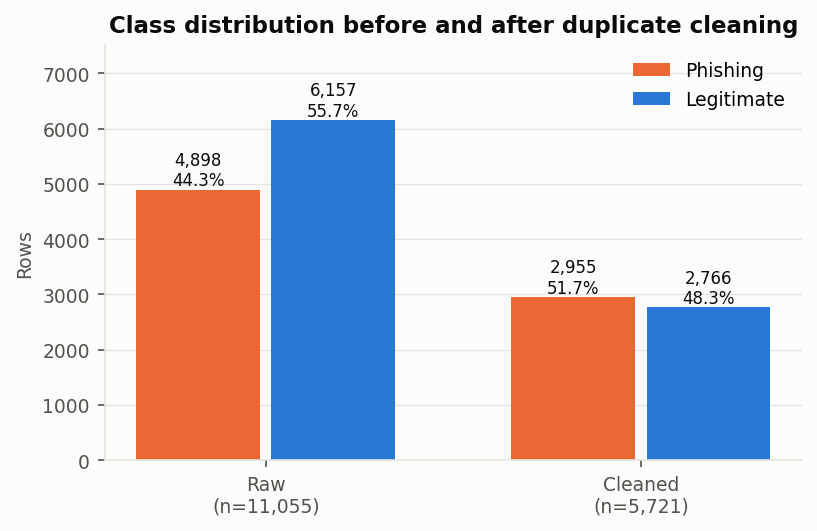

In [2]:
Image(filename=str(ROOT / R['figures']['class_distribution']))

**What it shows.** Phishing and legitimate counts in the raw file (11,055 rows) and after the approved cleaning (5,721 rows).

**Pattern.** The raw file is 44.3% phishing and 55.7% legitimate. After cleaning it is 51.7% phishing and 48.3% legitimate. Legitimate rows were duplicated more heavily than phishing rows, so deduplication reverses the majority class. Both versions are close to balanced, so no resampling is needed.

**Limitations.** The cleaned data counts *unique feature vectors*, not websites. A site profile that occurred 25 times now counts once. The class ratio of real web traffic is unknown and is very different from either version.

### 1.2 Duplicate statistics

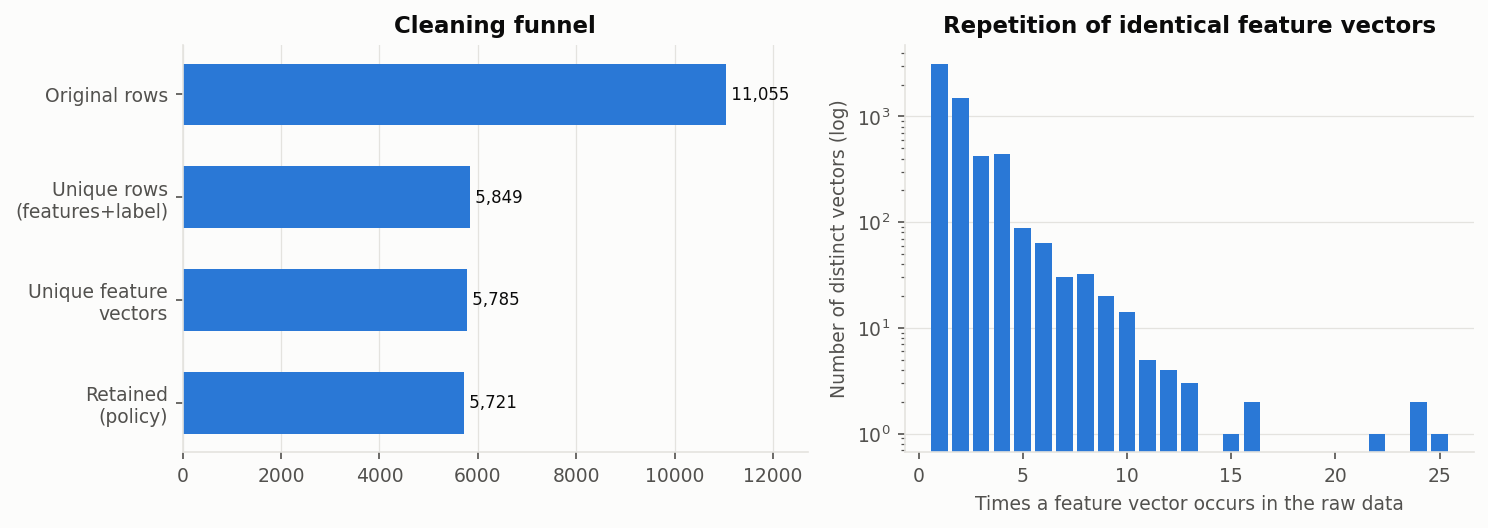

In [3]:
Image(filename=str(ROOT / R['figures']['duplicates']))

**What it shows.** Left: how many rows remain at each cleaning step. Right: how many distinct feature vectors occur 1, 2, …, 25 times in the raw data (log scale).

**Pattern.** About 47% of raw rows (5,206) are exact repeats. Most vectors occur once or twice, but a long tail repeats up to 25 times. Only 64 vectors carry both labels.

**Limitations.** With 30 coarse (2–3 level) indicators, different real websites can collapse to the same vector. Duplicates are therefore *not* necessarily data-entry errors, and the data cannot tell us which ones are.

### 1.3 Why duplicates matter for evaluation: the raw-split diagnostic

In [4]:
pd.Series(R["duplicate_leakage_diagnostic"])

raw_val_rows                               1659.0000
raw_val_rows_with_exact_twin_in_train      1055.0000
raw_val_overlap_percent                      63.5900
lookup_accuracy_on_overlapping_val_rows       0.9725
cleaned_val_overlap_percent                   0.0000
dtype: float64

This applies the *same* stratified split to the **raw** file, as a diagnostic only. About **63.6%** of raw
validation rows then have an identical feature vector in training. A pure look-up model (no learning; it just copies the
training label) is **97.3%** accurate on those rows. Any model that memorises well, such as an unconstrained tree or a forest,
would get inflated scores from this overlap. That is the main reason for deduplicating *before* splitting.
After cleaning, the overlap is 0% by construction.

### 1.4 Per-feature value counts (all cleaned rows, label-free)

In [5]:
vc = pd.DataFrame(R["value_counts_cleaned"]).T.reindex(columns=["-1", "0", "1"]).fillna(0).astype(int)
vc["n_levels"] = (vc > 0).sum(axis=1)
vc

,-1,0,1,n_levels
having_ip_address,0,0,0,0
url_length,0,0,0,0
shortining_service,0,0,0,0
having_at_symbol,0,0,0,0
double_slash_redirecting,0,0,0,0
prefix_suffix,0,0,0,0
having_sub_domain,0,0,0,0
sslfinal_state,0,0,0,0
domain_registration_length,0,0,0,0
favicon,0,0,0,0


22 features are binary and 8 are ternary. `redirect` uses {0, 1} instead of {−1, 1}. Several features are very
unbalanced, with one level used by only a few percent of rows (for example `rightclick = −1` and the `url_length = 0` level).
Imbalanced levels give noisy rate estimates, which is why intervals are shown later.

## 2. Feature analysis (training partition)

### 2.1 Feature values stacked by class

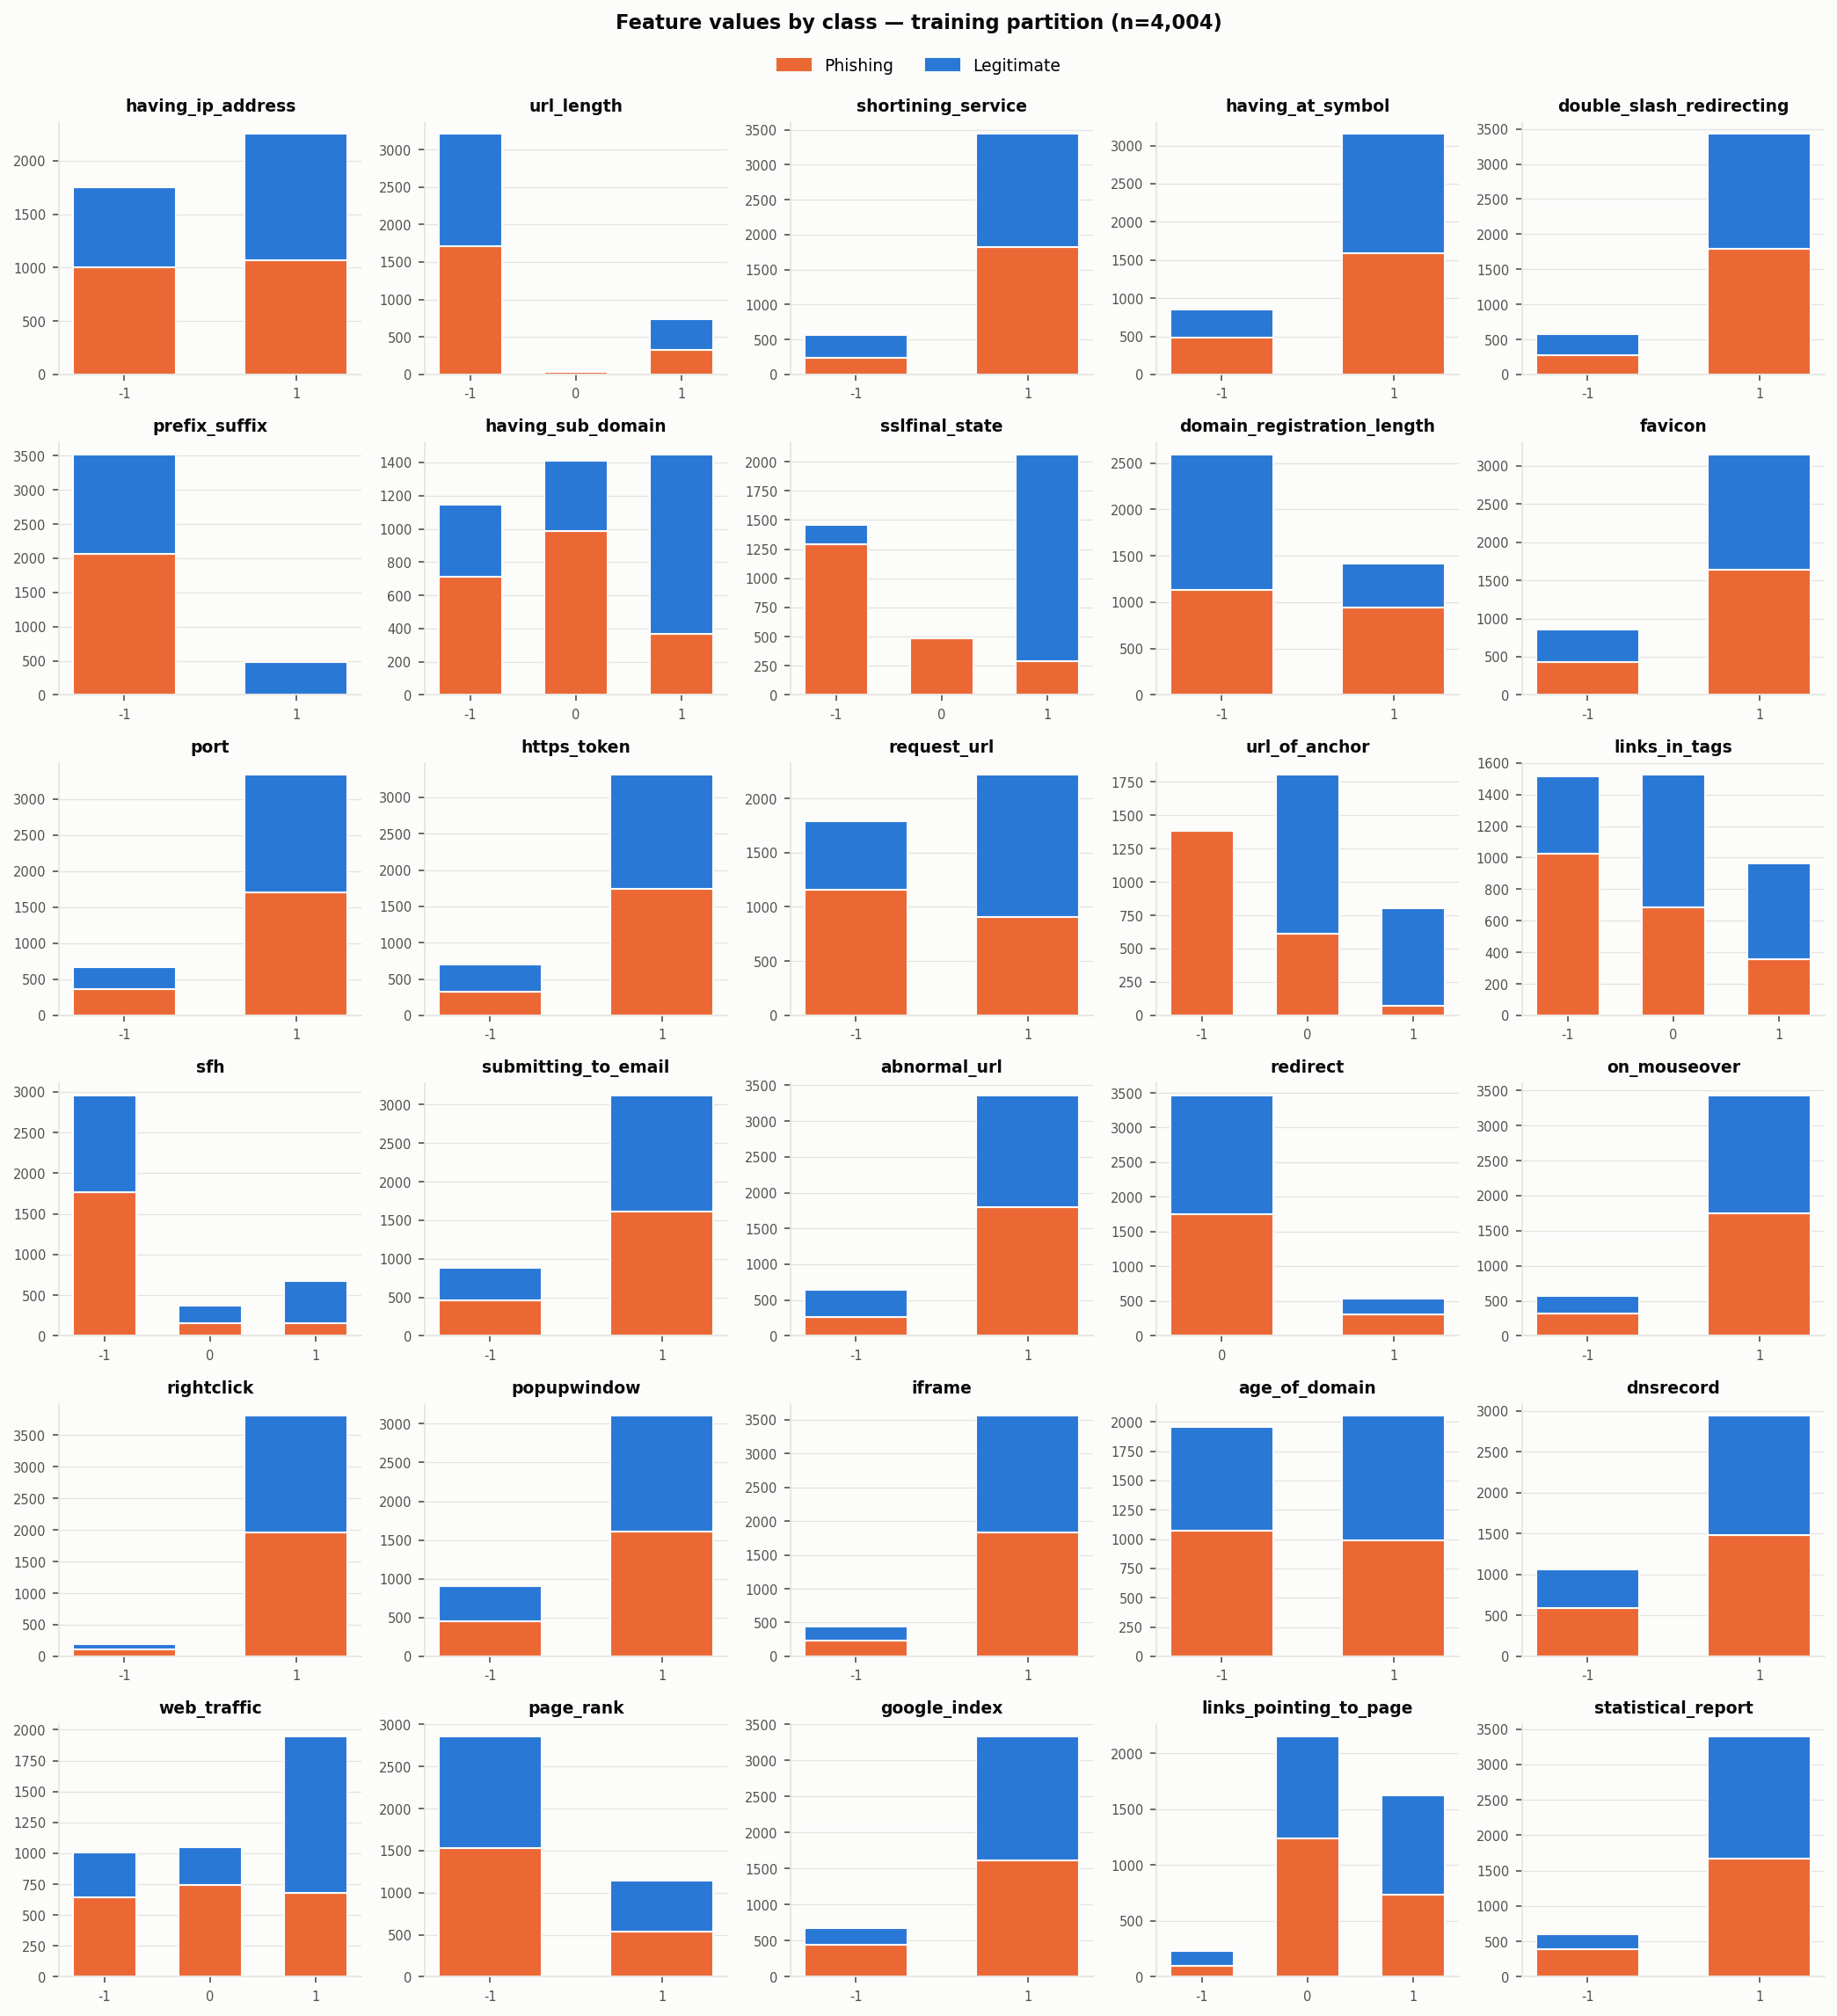

In [6]:
Image(filename=str(ROOT / R['figures']['values_by_class']))

**What it shows.** For each feature, the number of training rows with each value, split into phishing (orange) and legitimate (blue).

**Pattern.** Clear separation is visible for `sslfinal_state`, `url_of_anchor`, `prefix_suffix`, `having_sub_domain` and `web_traffic`. Many other features, such as `favicon`, `port`, `iframe` and `rightclick`, have almost the same class mix at every value. **`prefix_suffix = 1` contains no phishing rows at all**. In the raw file, all 4,898 phishing rows have `prefix_suffix = −1`.

**Limitations.** Counts depend on how the dataset was collected. Stacked heights make it hard to compare rates between values, which the next figure fixes.

### 2.2 Phishing rate for each feature value

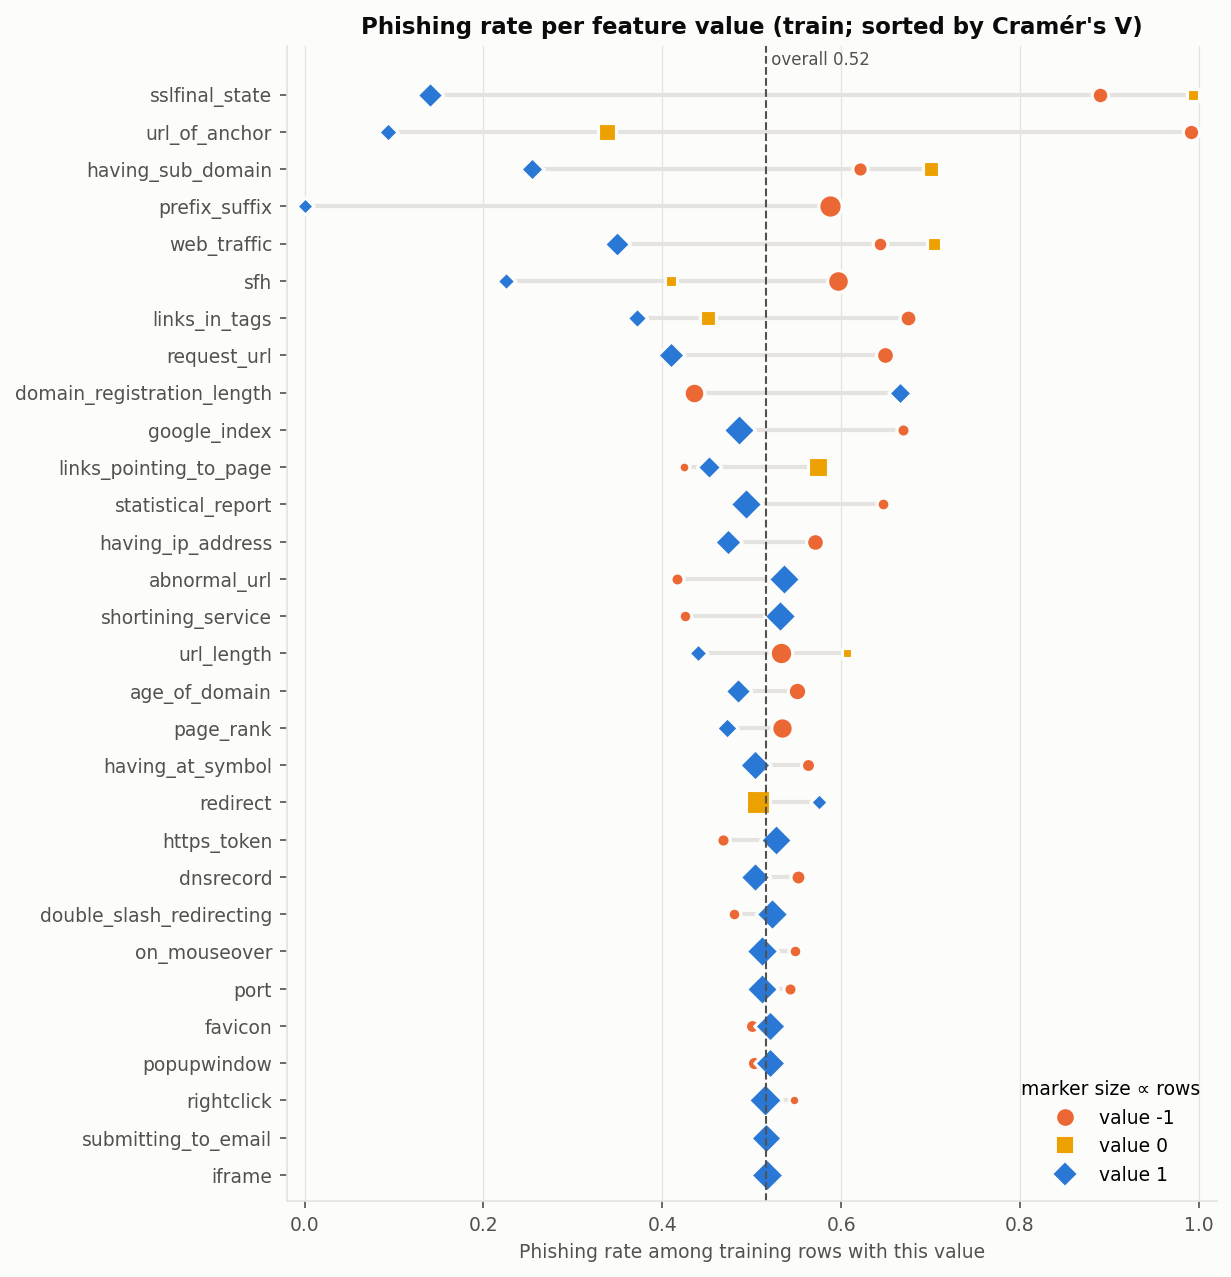

In [7]:
Image(filename=str(ROOT / R['figures']['phishing_rate']))

**What it shows.** Each row is a feature. Each marker is the share of training rows with that value that are phishing. Marker size is proportional to the number of rows. The dashed line is the overall rate (0.52).

**Pattern.** The documented order (−1 phishing, 0 suspicious, 1 legitimate) holds **monotonically** for `url_of_anchor`, `links_in_tags` and `sfh`. It is **not monotone** for `sslfinal_state` (0 → 99.4% > −1 → 88.9%), `having_sub_domain` and `web_traffic` (0 > −1 in both). `domain_registration_length` runs **opposite** to its documented rule (−1 → 43.5% vs 1 → 66.6%). Weak, *inverted* gaps also appear for `abnormal_url`, `shortining_service`, `https_token` and `double_slash_redirecting`.

**Limitations.** Rates come from 4,004 training rows; small levels (e.g. `url_length = 0`) are noisy. **Implication for Phase 3:** a linear model fed the raw −1/0/1 codes assumes equally spaced, monotone effects. The non-monotone ternary features argue for one-hot encoding, which will be tested on validation, not assumed.

### 2.3 Feature–label association (Cramér's V)

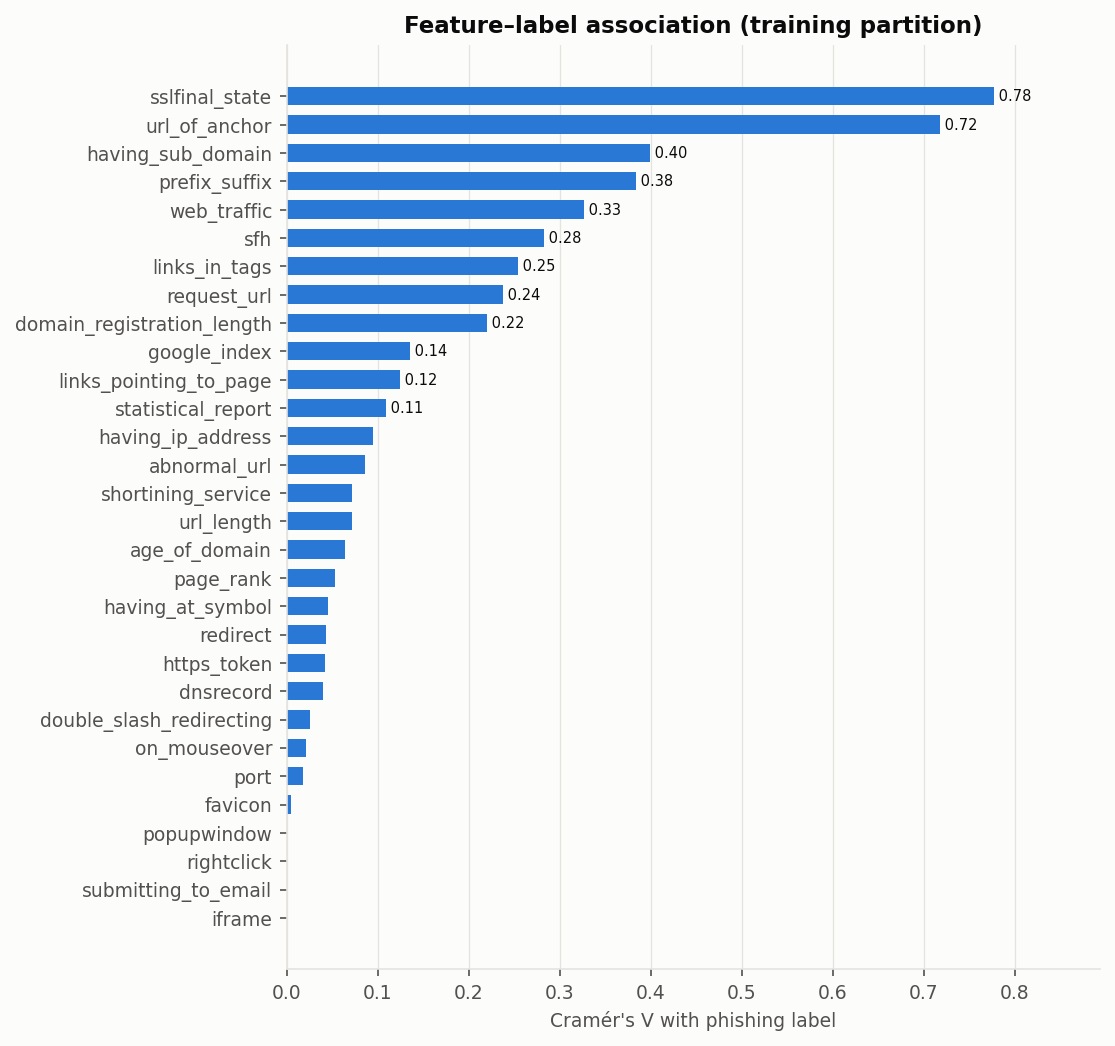

In [8]:
Image(filename=str(ROOT / R['figures']['target_association']))

**What it shows.** Bias-corrected Cramér's V between each feature and the label (0 = no association, 1 = perfect).

**Pattern.** Two features dominate: `sslfinal_state` (0.78) and `url_of_anchor` (0.72). A mid group follows (`having_sub_domain` 0.40, `prefix_suffix` 0.38, `web_traffic` 0.33, `sfh` 0.28, `links_in_tags` 0.25, `request_url` 0.24, `domain_registration_length` 0.22). 18 of the 30 features are below 0.1.

**Limitations.** Cramér's V is symmetric and ignores direction. It measures *marginal* association only: a feature with V ≈ 0 can still help in combination with others, and two strong features can carry the same information.

In [9]:
pd.DataFrame(R["target_association_train"])[["feature", "cramers_v", "mutual_info_bits", "phishing_rate_by_value", "n_by_value"]]

,feature,cramers_v,mutual_info_bits,phishing_rate_by_value,n_by_value
0,sslfinal_state,0.7778,0.5092,"{-1: 0.8894, 0: 0.9938, 1: 0.1402}","{-1: 1456, 0: 487, 1: 2061}"
1,url_of_anchor,0.7181,0.4676,"{-1: 0.9907, 0: 0.3381, 1: 0.0931}","{-1: 1397, 0: 1801, 1: 806}"
2,having_sub_domain,0.3996,0.1195,"{-1: 0.621, 0: 0.7009, 1: 0.2541}","{-1: 1145, 0: 1411, 1: 1448}"
3,prefix_suffix,0.3843,0.1406,"{-1: 0.588, 1: 0.0}","{-1: 3517, 1: 487}"
4,web_traffic,0.3268,0.0789,"{-1: 0.6431, 0: 0.7041, 1: 0.3498}","{-1: 1006, 0: 1051, 1: 1947}"
5,sfh,0.2827,0.0602,"{-1: 0.5964, 0: 0.4096, 1: 0.2247}","{-1: 2956, 0: 376, 1: 672}"
6,links_in_tags,0.2538,0.0476,"{-1: 0.6748, 0: 0.4508, 1: 0.3714}","{-1: 1516, 0: 1524, 1: 964}"
7,request_url,0.2373,0.0412,"{-1: 0.6488, 1: 0.4097}","{-1: 1788, 1: 2216}"
8,domain_registration_length,0.2203,0.0357,"{-1: 0.435, 1: 0.666}","{-1: 2591, 1: 1413}"
9,google_index,0.1356,0.0137,"{-1: 0.6687, 1: 0.4859}","{-1: 670, 1: 3334}"


### 2.4 Pairwise association heatmap

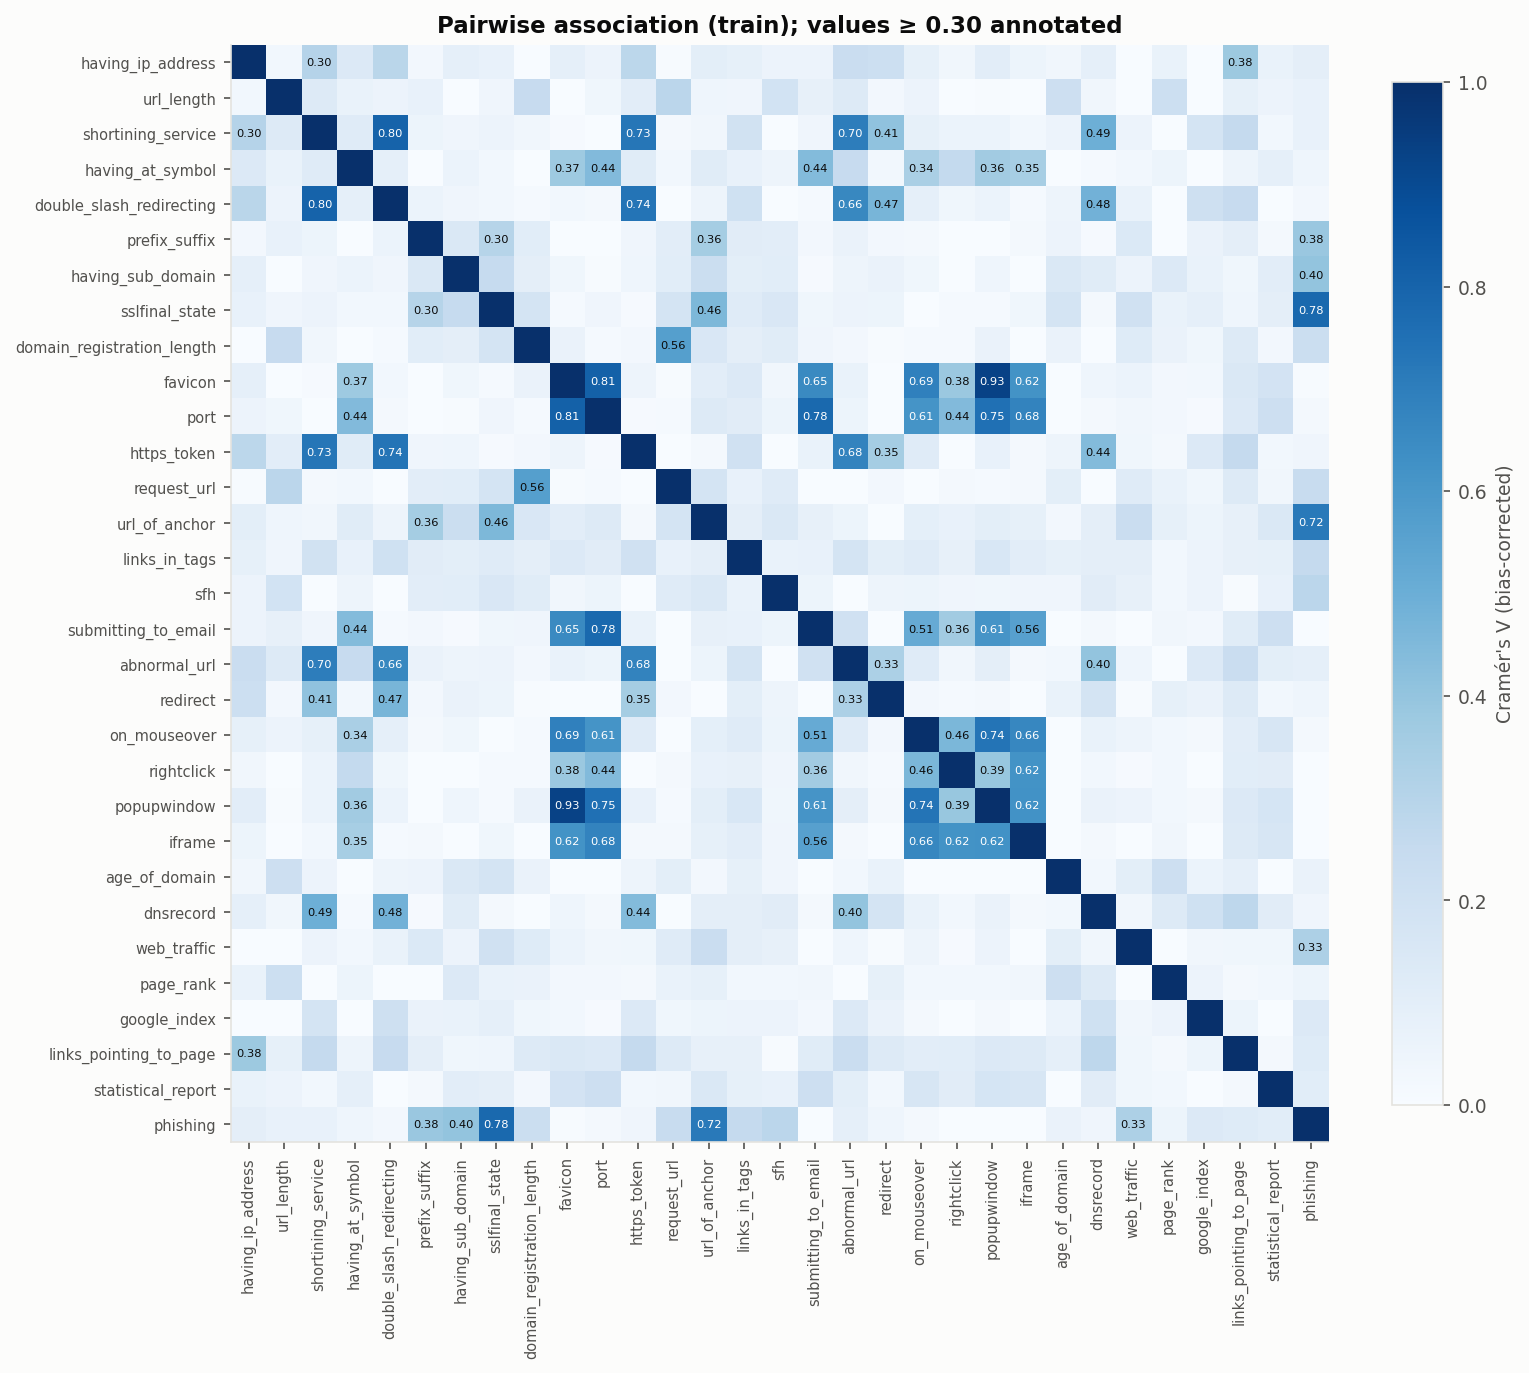

In [10]:
Image(filename=str(ROOT / R['figures']['association_heatmap']))

**What it shows.** Bias-corrected Cramér's V between every pair of features and the label (training partition). Cramér's V is used instead of Pearson correlation because the variables are categorical codes.

**Pattern.** There are two tight clusters that are **almost unrelated to the label**: (a) the page-script/HTML group `favicon`, `port`, `popupwindow`, `on_mouseover`, `iframe`, `submitting_to_email`, `rightclick` (e.g. favicon–popupwindow 0.93, favicon–port 0.81), and (b) the URL-structure group `shortining_service`, `double_slash_redirecting`, `https_token`, `abnormal_url`, `dnsrecord`, `redirect` (0.40–0.80). The two predictive features `sslfinal_state` and `url_of_anchor` are only moderately associated with each other (0.46).

**Limitations.** Such strong co-occurrence among conceptually unrelated checks (e.g. favicon origin and open ports) may reflect how the features were extracted or collected, for example the same sites failing several checks together. This cannot be verified from the data. Redundancy matters for Logistic Regression coefficients (they become unstable) and for impurity importance (credit gets split between correlated features).

### 2.5 Single-feature validation ROC-AUC

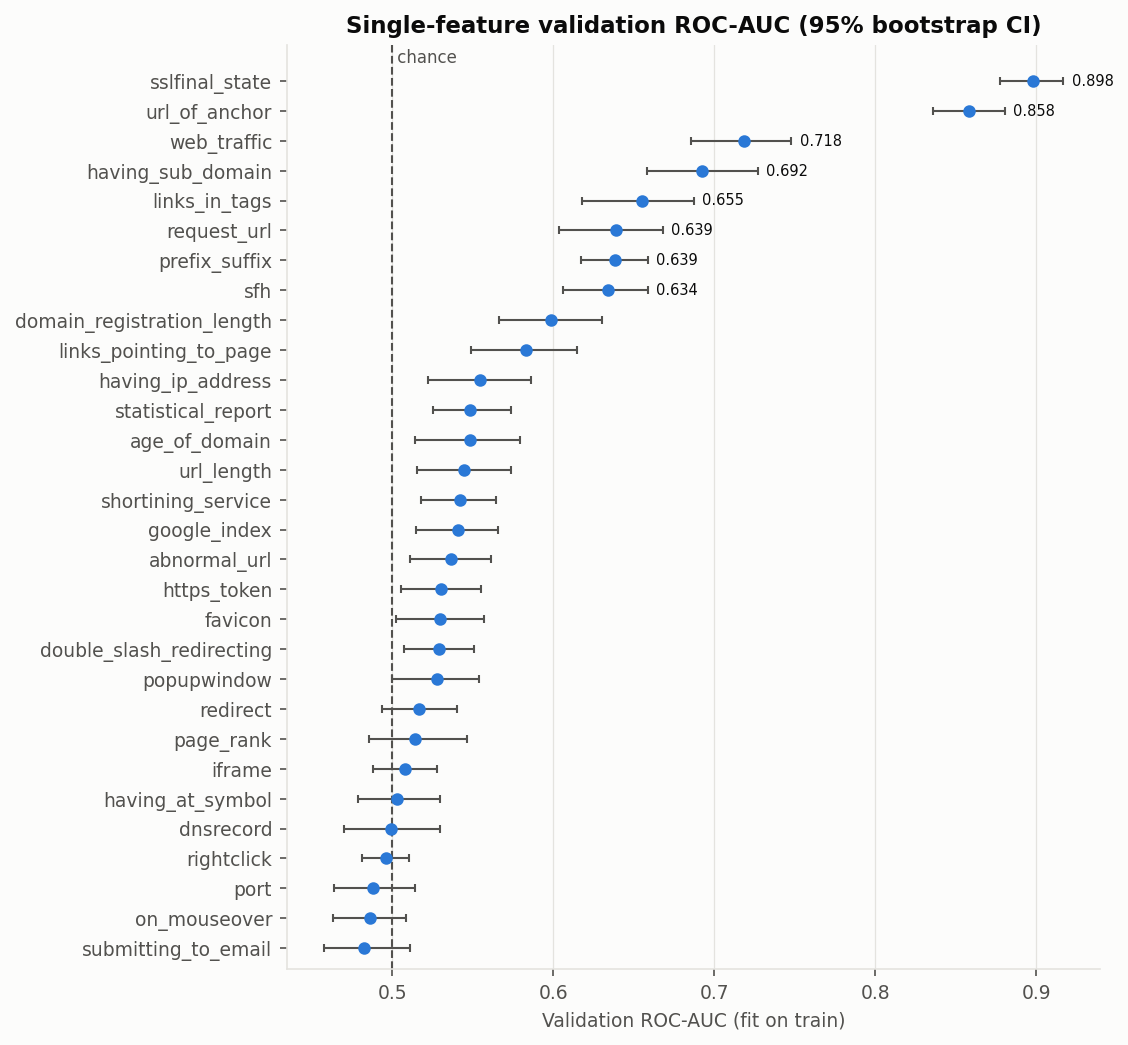

In [11]:
Image(filename=str(ROOT / R['figures']['single_feature_auc']))

**What it shows.** For each feature, a one-feature model is fitted on **train** (Laplace-smoothed phishing rate per value) and scored on **validation**. Bars are 95% bootstrap intervals (1,000 resamples of the validation set).

**Pattern.** `sslfinal_state` 0.898 [0.878, 0.917] and `url_of_anchor` 0.858 [0.836, 0.880] stand far above the rest. `web_traffic` (0.718) and `having_sub_domain` (0.692) come next. 9 features (`redirect`, `page_rank`, `iframe`, `having_at_symbol`, `dnsrecord`, `rightclick`, `port`, `on_mouseover`, `submitting_to_email`) have intervals that include 0.5, so on their own they are indistinguishable from chance. Train and validation AUCs are close, so these one-feature models are not overfitting.

**Limitations.** No single feature is close to 1.0, so no feature looks like a target copy. `sslfinal_state` is strong but plausible (certificate validity and issuer trust are known phishing signals). `prefix_suffix` has a pure level but only a modest AUC (0.639), because that level covers just 12% of rows. Validation has 858 rows, so differences under about 0.03 AUC are within noise.

In [12]:
pd.DataFrame(R["single_feature_val_auc"])

,feature,val_roc_auc,ci_low,ci_high,train_roc_auc
0,sslfinal_state,0.8976,0.8776,0.9168,0.8970
1,url_of_anchor,0.8583,0.8356,0.8803,0.8757
2,web_traffic,0.7182,0.6854,0.7479,0.6704
3,having_sub_domain,0.6924,0.6583,0.7268,0.7061
4,links_in_tags,0.6550,0.6176,0.6872,0.6346
5,request_url,0.6391,0.6036,0.6683,0.6183
6,prefix_suffix,0.6386,0.6170,0.6585,0.6258
7,sfh,0.6339,0.6061,0.6589,0.6240
8,domain_registration_length,0.5987,0.5662,0.6304,0.6056
9,links_pointing_to_page,0.5829,0.5486,0.6149,0.5639


### 2.6 Distribution of '−1' codes per row, by class

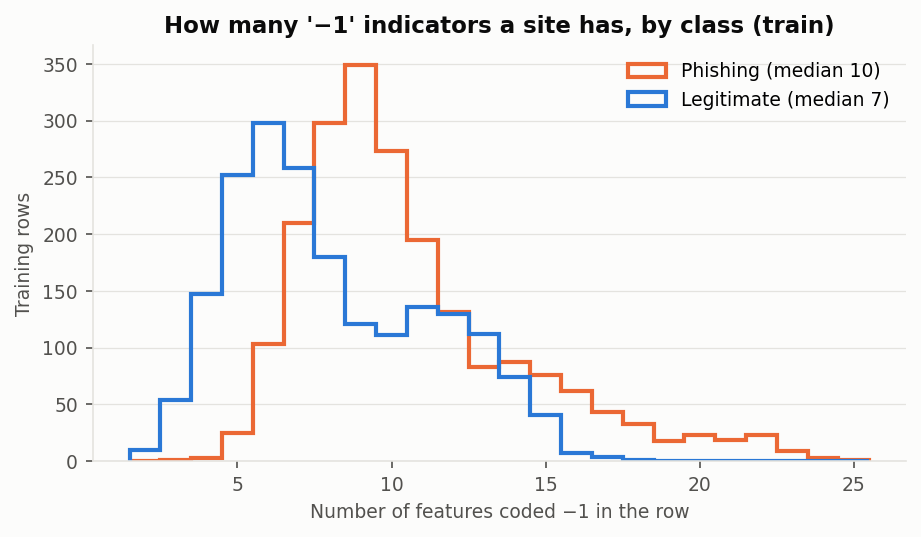

In [13]:
Image(filename=str(ROOT / R['figures']['minus_one_count']))

**What it shows.** For each training row, the number of features coded −1. Outlined histograms by class.

**Pattern.** Phishing rows carry more −1 codes (median 10 vs 7). The distributions overlap heavily between about 7 and 14. A simple count is informative but far from sufficient.

**Limitations.** This treats every feature as equal. Because some features run against their documented direction, −1 is not a uniform 'phishing' signal.

## 3. Summary of exploratory findings

| # | Finding | Consequence for later phases |
|---|---|---|
| 1 | 47% of raw rows are exact duplicates. On a raw split, 63.6% of validation rows have a training twin, and look-up is 97.3% accurate on them | Deduplicate before splitting (approved). Report raw-data scores only as a labelled diagnostic |
| 2 | Cleaning flips the class balance to 51.7% phishing / 48.3% legitimate | Classes are near-balanced; no resampling. Class weighting optional |
| 3 | Two features dominate (`sslfinal_state`, `url_of_anchor`; val AUC ≈ 0.90 / 0.86); 9 features are indistinguishable from chance on their own | Expect strong but not perfect performance. Test feature selection in Phase 8 |
| 4 | `sslfinal_state`, `having_sub_domain` and `web_traffic` are non-monotone in their codes | Compare one-hot vs raw codes for Logistic Regression in Phase 3/4 |
| 5 | `prefix_suffix = 1` is 100% legitimate; `domain_registration_length` runs against its documented rule | Not target leakage (no column copies the label), but possible collection artifacts. Ablation in Phase 8; flag in `features.md` |
| 6 | Two clusters of highly inter-associated features with weak label association | Expect unstable LR coefficients and split impurity importance; check with L2 and permutation importance |

All label-dependent statistics come from the training partition; predictive diagnostics come from validation.
The test partition (859 rows) has not been examined.